# Exploration of h5 file



In [1]:
import numpy as np
from matplotlib import pyplot as plt
import h5py
import scipy.io as sio

#to visualize header xml
import lxml.etree as etree

# load defined functions from utils.py
from utils import *

# Loading file, getting k space data

## Infos regarding h5 file and h5py package
.h5 files opened as h5py.File that follows the [ISMRM Data Format (MRD)](https://ismrmrd.readthedocs.io/en/latest/). <br>
The file ows 3 types of informations accessible via the keys : ['ismrmrd_header', 'kspace', 'reconstruction_rss'] <br>
In the 'ismrmrd_header' are informations about the configuration of the IRM acquisition as xml file. <br>
'kspace' holds the kspace data and 'reconstruction_rss' the reconstructed images from the IRM


In [2]:
#loading .h5 file with The h5py package (Pythonic interface to the HDF5 binary data format) as a h5py._hl.files.File
file_path = "data/file_brain_AXT2_205_2050058.h5"
image_file = h5py.File(file_path)
type(image_file)

h5py._hl.files.File

In [3]:
list(image_file.keys())

['ismrmrd_header', 'kspace', 'reconstruction_rss']

In [4]:
header = image_file['ismrmrd_header'][()]
header

b'<?xml version="1.0" encoding="utf-8"?>\n<ismrmrdHeader xmlns="http://www.ismrm.org/ISMRMRD" xmlns:xs="http://www.w3.org/2001/XMLSchema" xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance" xsi:schemaLocation="http://www.ismrm.org/ISMRMRD ismrmrd.xsd">\n   <studyInformation>\n      <studyTime>17:12:13</studyTime>\n   </studyInformation>\n   <measurementInformation>\n      <measurementID>141513_2549038_2549046_561</measurementID>\n      <patientPosition>HFS</patientPosition>\n      <protocolName>AX</protocolName>\n      <frameOfReferenceUID>1.3.12.2.1107.5.2.18.141513.1.20180208164929957.0.0.5009</frameOfReferenceUID>\n   </measurementInformation>\n   <acquisitionSystemInformation>\n      <systemVendor>SIEMENS</systemVendor>\n      <systemModel>Aera</systemModel>\n      <systemFieldStrength_T>1.494</systemFieldStrength_T>\n      <relativeReceiverNoiseBandwidth>0.793</relativeReceiverNoiseBandwidth>\n      <receiverChannels>20</receiverChannels>\n      <coilLabel>\n         <coilNumber

In [5]:
type(image_file['ismrmrd_header'])

h5py._hl.dataset.Dataset

In [6]:
x = etree.parse(header)
etree.tostring(x, pretty_print=True)

OSError: Error reading file '<?xml version="1.0" encoding="utf-8"?>
<ismrmrdHeader xmlns="http://www.ismrm.org/ISMRMRD" xmlns:xs="http://www.w3.org/2001/XMLSchema" xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance" xsi:schemaLocation="http://www.ismrm.org/ISMRMRD ismrmrd.xsd">
   <studyInformation>
      <studyTime>17:12:13</studyTime>
   </studyInformation>
   <measurementInformation>
      <measurementID>141513_2549038_2549046_561</measurementID>
      <patientPosition>HFS</patientPosition>
      <protocolName>AX</protocolName>
      <frameOfReferenceUID>1.3.12.2.1107.5.2.18.141513.1.20180208164929957.0.0.5009</frameOfReferenceUID>
   </measurementInformation>
   <acquisitionSystemInformation>
      <systemVendor>SIEMENS</systemVendor>
      <systemModel>Aera</systemModel>
      <systemFieldStrength_T>1.494</systemFieldStrength_T>
      <relativeReceiverNoiseBandwidth>0.793</relativeReceiverNoiseBandwidth>
      <receiverChannels>20</receiverChannels>
      <coilLabel>
         <c

## Informations from header
number of coils : 20 is in receiverChannels section <br>
matrixSize 640 x; y 320; z1 in  encoding and encodedSpace section <br>
reconSpace : matrixSize :x 320; 320 y; z >1 <br>
trajectory cartesian <br>
sequenceParameters :  TR 6160 ; TE 102; TI 100; flipAngle_deg 150; sequence_type TurboSpinEcho; echo_spacing 10.24

#  Exploring kspace data
- kspace are in h5py._hl.dataset.Dataset format and are converted in numpy array <br>
In multi-coil MRIs, **k-space has the following shape: (number of slices, number of coils, height, width)** <br>
Here (16, 20, 640, 320) fits with informations from ismrmrd_header : matrixSize 640 x; y 320; z1 Number of coils = 20  == receiverChannels and 16 slices
receiverChannels <br>




## kspace dimension and scale

In [7]:
image_file['kspace']

<HDF5 dataset "kspace": shape (16, 20, 640, 320), type "<c8">

In [8]:
volume_kspace = image_file['kspace'][()]
volume_kspace

array([[[[ 1.75740570e-06+6.81169331e-06j,
           1.25519000e-06-5.17186709e-06j,
           1.50804408e-06+3.29222530e-07j, ...,
           8.75955448e-06-4.50666994e-06j,
          -2.32155435e-06-2.65426934e-08j,
           2.01351941e-06-9.74535942e-06j],
         [-3.48174945e-06+1.07351225e-05j,
          -1.33318827e-06-6.89411536e-07j,
           3.45986336e-06+5.18048182e-07j, ...,
           9.63825732e-06-1.33861322e-05j,
           3.30922194e-06+6.57211058e-06j,
           8.26781616e-06+5.82938083e-06j],
         [-2.32923776e-06+6.43986277e-06j,
          -6.49155118e-06-4.31225635e-06j,
           1.31572597e-06+3.51760536e-06j, ...,
           4.86616045e-07-7.25430436e-06j,
          -5.52111305e-06+4.74252738e-06j,
          -3.01422551e-06+8.33161175e-06j],
         ...,
         [-3.00281681e-06-6.19934872e-06j,
           5.08851372e-06-6.53346069e-06j,
          -1.13970600e-06+1.77975744e-06j, ...,
           3.91528010e-06+9.08435322e-06j,
          -4.6573

In [9]:
volume_kspace.shape

(16, 20, 640, 320)

In [10]:
type(volume_kspace)

numpy.ndarray

### kspace data points and Min and max values
The acquired [MR signal](https://mriquestions.com/data-for-k-space.html) is already in a Fourier-like format suitable for filling the k-space matrix.
The MR signal is detected in quadrature. Each digitized data point of the MR signal can be represented as a **complex number**, with real and imaginary components.<br>
Alternatively, **each data point can be defined as having a magnitude and phase**, computed by simple trigonometric relations. 

Select kspace signal from 1 slice and 1 coil (shape 320x320) and get valeur max : (2.5852083292589466e-05+3.756152146597284e-06j); <br> valeur min : (-4.216375406834455e-05-1.7576234527755557e-06j) 


In [11]:
volume_kspace[0,0,:,:]

array([[ 1.7574057e-06+6.81169331e-06j,  1.2551900e-06-5.17186709e-06j,
         1.5080441e-06+3.29222530e-07j, ...,
         8.7595545e-06-4.50666994e-06j, -2.3215543e-06-2.65426934e-08j,
         2.0135194e-06-9.74535942e-06j],
       [-3.4817494e-06+1.07351225e-05j, -1.3331883e-06-6.89411536e-07j,
         3.4598634e-06+5.18048182e-07j, ...,
         9.6382573e-06-1.33861322e-05j,  3.3092219e-06+6.57211058e-06j,
         8.2678162e-06+5.82938083e-06j],
       [-2.3292378e-06+6.43986277e-06j, -6.4915512e-06-4.31225635e-06j,
         1.3157260e-06+3.51760536e-06j, ...,
         4.8661605e-07-7.25430436e-06j, -5.5211131e-06+4.74252738e-06j,
        -3.0142255e-06+8.33161175e-06j],
       ...,
       [-3.0028168e-06-6.19934872e-06j,  5.0885137e-06-6.53346069e-06j,
        -1.1397060e-06+1.77975744e-06j, ...,
         3.9152801e-06+9.08435322e-06j, -4.6573114e-06-4.78117727e-06j,
         2.0097941e-06+6.16931356e-06j],
       [ 9.9523459e-06-7.81146809e-07j, -1.8391293e-06-3.89129855e-0

In [12]:
# selecting kspace from 1 slice and 1st coil
kspace_1slice_1coil = volume_kspace[0,0,:,:]
kspace_1slice_1coil.shape

(640, 320)

In [13]:
kspace_1slice_1coil[0].max()

np.complex64(1.72609e-05+5.137408e-06j)

In [14]:
# with np.abs we get only the real component
np.abs(kspace_1slice_1coil[0].max())

np.float32(1.8009208e-05)

In [15]:
kspace_1slice_1coil.min()

np.complex64(-0.00042778673-0.00013069808j)

In [16]:
# with np.abs we get only the real component
np.abs(kspace_1slice_1coil[0].min())

np.float32(1.529146e-05)

## Multi-coil signal

### Showing the 20 coils kspace signal separately for 1 slice (middle slice from 16 one) 
The [glow](https://medium.com/@nadavlevi/visualising-mri-data-in-python-fe010c4a1c54) in the centre of the k-space image represents the lower spatial frequencies, which contains the bulk of the image contrast information. As we move away from this central glow, the finer details and edges, representing the higher spatial frequencies, become apparent. These outer regions may appear fainter, but they hold vital information that sharpens our final image. In essence the outer region carries the fine details and edges of the image

In [17]:
middle_index = volume_kspace.shape[0] //2
middle_index

8

In [18]:
slice_kspace = volume_kspace[middle_index] # Choosing the middle slice of this volume
slice_kspace.shape

(20, 640, 320)

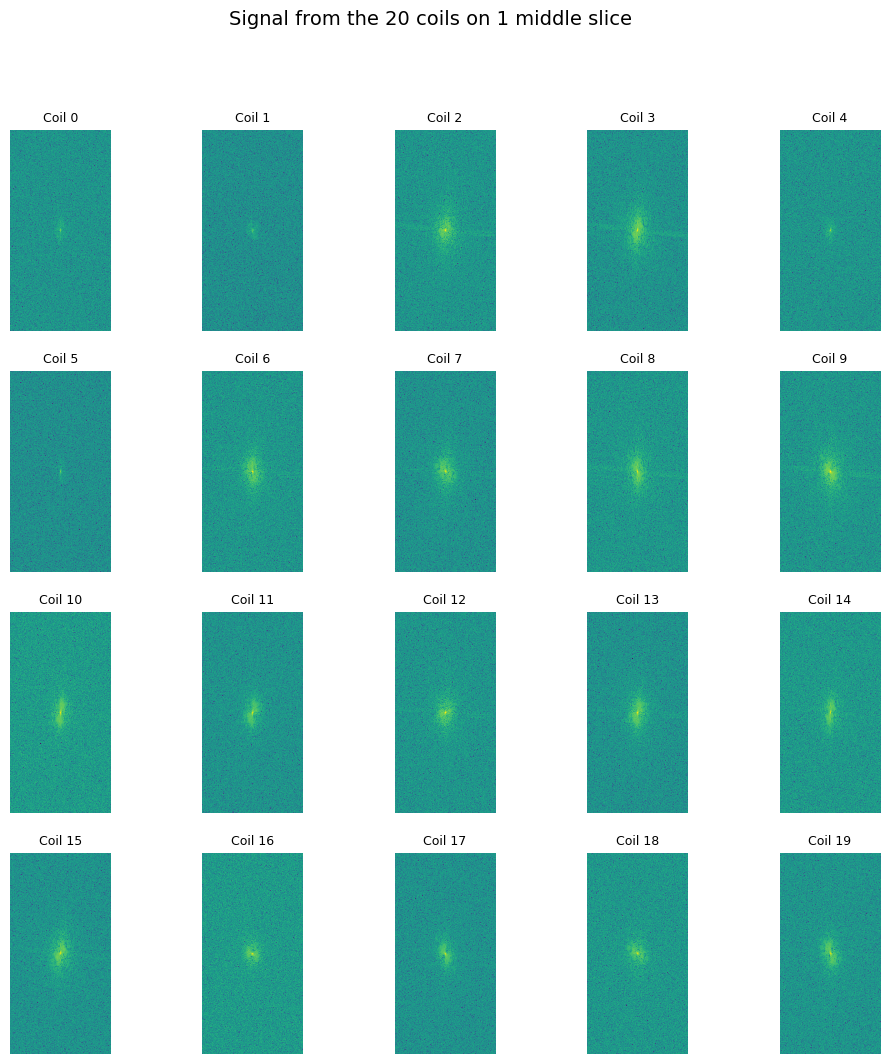

In [ ]:
data_to_show = np.log(np.abs(slice_kspace) + 1e-9)
show_grid(data_to_show, coil_indices=[i for i in range(0, 20)], cmap='viridis', nrows=4, ncols=5, fig_size=(12,12))

### From kspace to complex-valued image (middle slice from 16 one and last coil signal only)
To get from k-space to an actual image, we use the inverse Fourier transform (inverse_fft2_shift_1slice). This process translates the frequency data from k-space into spatial information, giving us a clear image. After applying the inverse Fourier transform to our k-space data, what we get isn’t just a regular image but a complex-valued image. This translates to each pixel having both a real and imaginary component. <br>
https://medium.com/@nadavlevi/visualising-mri-data-in-python-fe010c4a1c54

In [20]:
# get images from kspace for the 8th slice and the 20 coils
image_8th_slice = inverse_fft2_shift_1slice(slice_kspace)
image_8th_slice.shape

(20, 640, 320)

In [21]:
# get images from kspace for the 8th slice and only the last coil
image_8th_slice_last_coil= image_8th_slice[19,:,:]

In [22]:
# get kspace from kspace for the 8th slice and the last coil and apply log and abs to plot
kspace_8th_slice_last_coil = np.log(np.abs(slice_kspace[19,:,:]) + 1e-9)

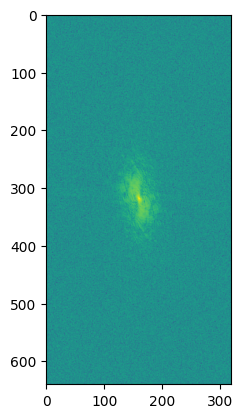

In [23]:
plt.imshow(kspace_8th_slice_last_coil)

In [24]:
# Extract the magnitude of the image data.
magnitude_data = np.abs(image_8th_slice_last_coil)

# Extract the phase of the image data.
phase_data = np.angle(image_8th_slice_last_coil)

# Separate out the real component of the image data.
real_data = np.real(image_8th_slice_last_coil)

# Separate out the imaginary component of the image data.
imaginary_data = np.imag(image_8th_slice_last_coil)

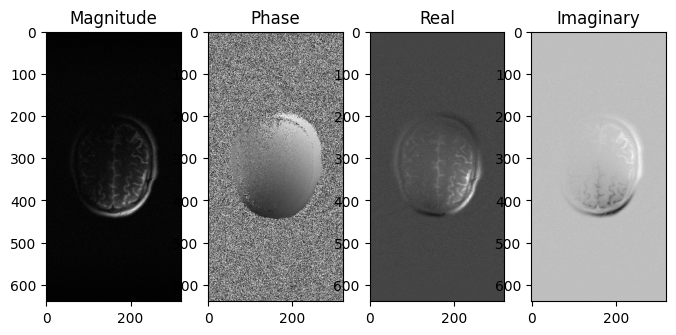

In [25]:
fig = plt.figure(figsize=(8,16))
list_plot = [magnitude_data, phase_data, real_data, imaginary_data]
list_title = ["Magnitude", "Phase", "Real", "Imaginary"]
for i in range(len(list_plot)):
    plt.subplot(1, len(list_plot), i + 1)
    plt.gca().set_title(list_title[i])
    plt.imshow(list_plot[i], cmap="gray")

### Showing the images from 20 coils signal separately for 1 slice (middle slice from 16 one) 

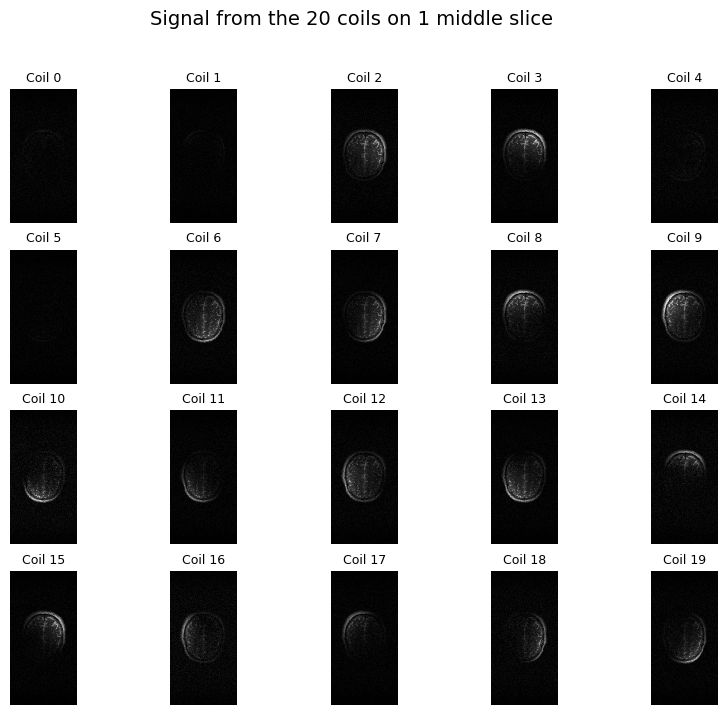

In [ ]:
show_grid(np.abs(image_8th_slice), cmap='gray', nrows=4, ncols=5, fig_size=(10,8))

In [27]:
# get images from ksapce
image_8th_slice = inverse_fft2_shift_1slice(slice_kspace)
image_8th_slice.shape

(20, 640, 320)

## Combining multi coil signal
Combining multi-coil images into   a single image by computing the pixel-wise root-sum-of-squares (RSS) across the coil dimension. Call rsos function

### Combining signal from the 20 coils on the middle slice

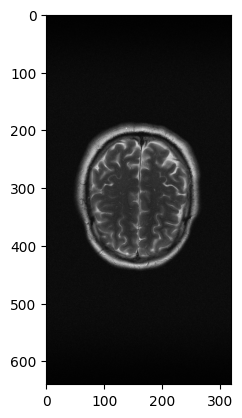

In [28]:
# Combine multi-coil data using Root Sum of Squares (RSS) to create magnitude image
magnitude_slice = rsos(image_8th_slice, 0)
plt.imshow(magnitude_slice, cmap='gray')

In [29]:
"""# Combine multi-coil data using Root Sum of Squares (RSS) to create magnitude image
magnitude_slice = np.sqrt(np.sum(np.abs(inverse_fft2_shift_1slice(slice_kspace))**2, axis=0))
plt.imshow(magnitude_slice, cmap='gray')"""

"# Combine multi-coil data using Root Sum of Squares (RSS) to create magnitude image\nmagnitude_slice = np.sqrt(np.sum(np.abs(inverse_fft2_shift_1slice(slice_kspace))**2, axis=0))\nplt.imshow(magnitude_slice, cmap='gray')"

### Combining signal from the 20 coils on the 16 slices

In [30]:
number_of_slices = volume_kspace.shape[0]
number_of_slices

16

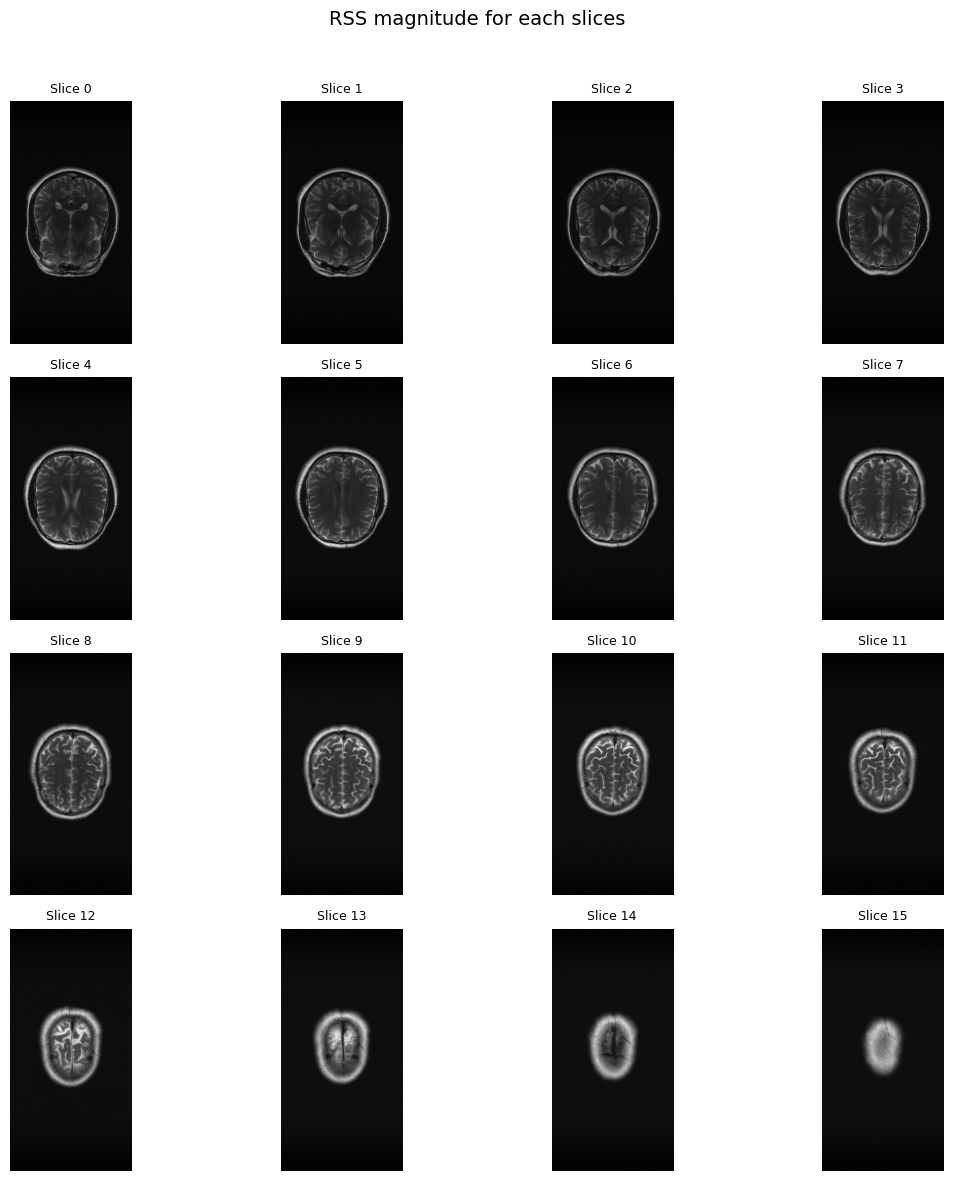

In [31]:
# Plot all 16 slices in a 4x4 grid (RSS magnitude)
number_of_slices = volume_kspace.shape[0]
fig, axes = plt.subplots(4, 4, figsize=(12,12))
axes = axes.flatten()
for idx, ax in enumerate(axes):
    if idx >= number_of_slices:
        ax.axis('off')
        continue
    # compute RSS magnitude for slice idx
    ksp = volume_kspace[idx]
    img_coils = inverse_fft2_shift_1slice(ksp)
    magnitude_slice = rsos(img_coils, 0)
    ax.imshow(magnitude_slice, cmap='gray')
    ax.set_title(f'Slice {idx}', fontsize=9)
    ax.axis('off')
fig.suptitle('RSS magnitude for each slices', fontsize=14)
plt.tight_layout(rect=[0,0,1,0.96])

#  Exploring reconstruction_rss
contains the reconstructed multi coil combined images from the machine

In [32]:
reconstruction_rss = image_file['reconstruction_rss']
reconstruction_rss

<HDF5 dataset "reconstruction_rss": shape (16, 320, 320), type "<f4">

In [33]:
reconstruction_rss[8,:,:]

array([[3.8898746e-05, 5.1376541e-05, 3.6700258e-05, ..., 5.1690997e-05,
        4.6884361e-05, 4.0988842e-05],
       [4.1853909e-05, 4.0649571e-05, 5.2714655e-05, ..., 3.7173973e-05,
        3.3006319e-05, 4.1978376e-05],
       [3.8560440e-05, 3.7064987e-05, 4.4267515e-05, ..., 4.6930796e-05,
        4.1076586e-05, 3.9220617e-05],
       ...,
       [4.9134662e-05, 3.5822275e-05, 3.2133976e-05, ..., 6.3452600e-05,
        5.0631777e-05, 3.4236262e-05],
       [5.0423230e-05, 3.8983937e-05, 4.0205072e-05, ..., 4.5625668e-05,
        4.8356003e-05, 4.2775311e-05],
       [4.2391712e-05, 4.5865538e-05, 3.8040373e-05, ..., 4.0683495e-05,
        3.9276500e-05, 4.3930388e-05]], dtype=float32)

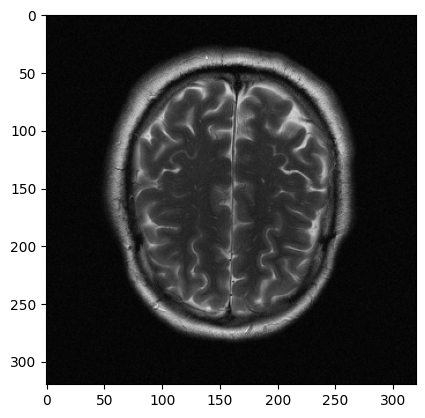

In [34]:
plt.imshow(reconstruction_rss[8,:,:], cmap= "grey")

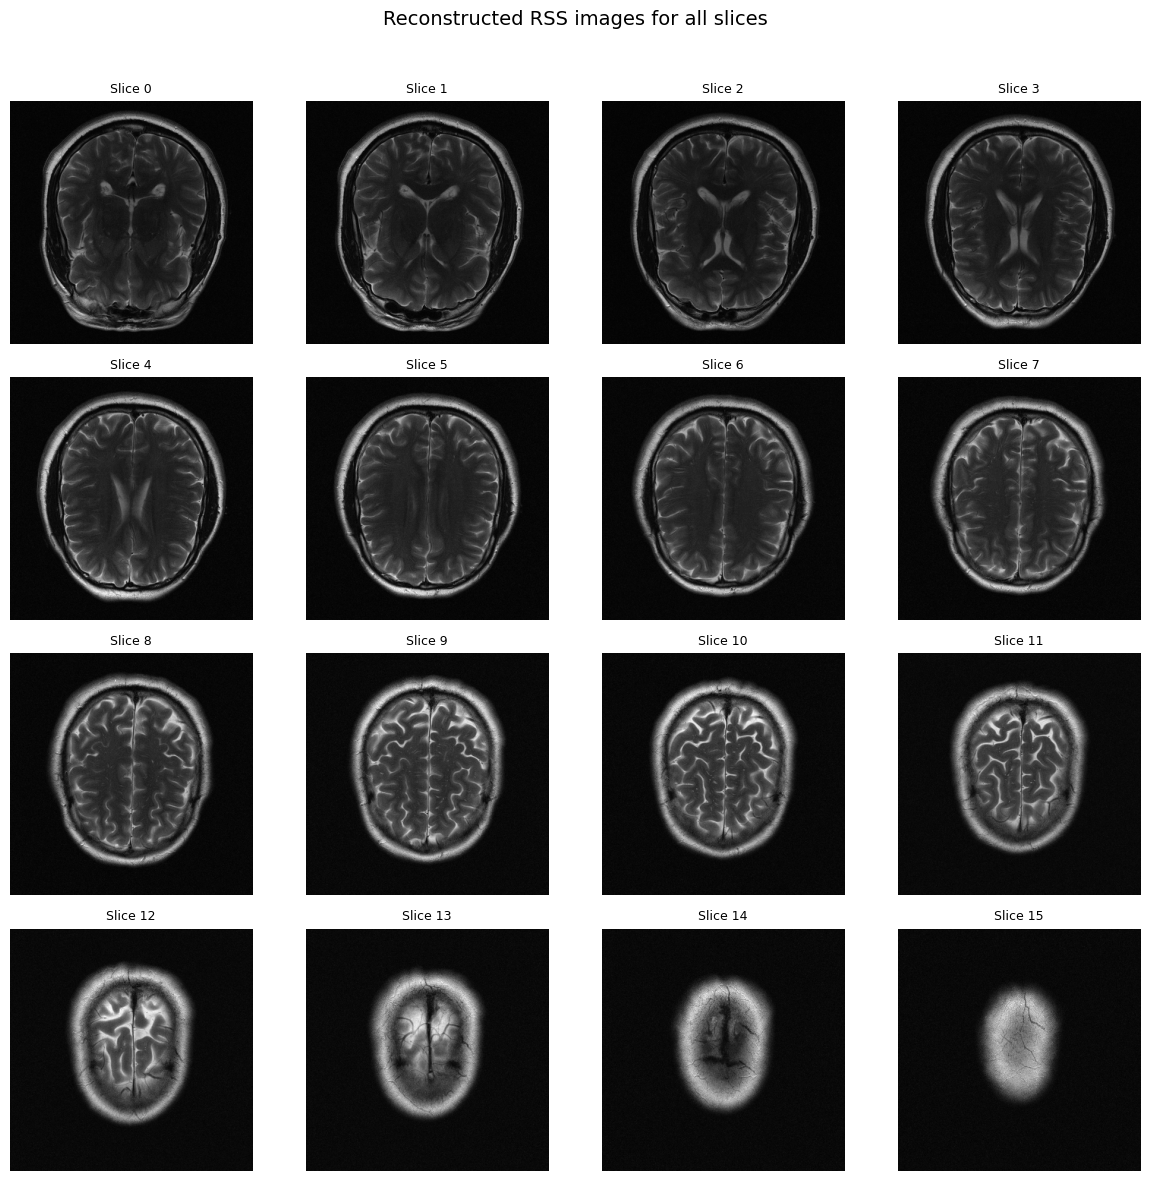

In [35]:
# Plot all 16 slices from reconstruction_rss in a 4x4 grid
num_slices = reconstruction_rss.shape[0]
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
axes = axes.flatten()

for idx, ax in enumerate(axes):
    if idx >= num_slices:
        ax.axis('off')
        continue
    ax.imshow(reconstruction_rss[idx, :, :], cmap='gray')
    ax.set_title(f'Slice {idx}', fontsize=9)
    ax.axis('off')

fig.suptitle('Reconstructed RSS images for all slices', fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()